# Pairs trading: distance vs cointegration vs mixed copula
**Papers:** (1) Sabino da Silva, Ziegelmann & Caldeira, *Mixed Copula Pairs Trading on the S&P 500*; (2) Rad, Low & Faff (2016), *The profitability of pairs trading strategies* (used here for the PnL / performance framework, Sections 4.4-4.5).

**Pairs:** AAPL/GOOG, IBM/SPY, DIA/SPY.


**some deviations :** with only 3 pairs there is no top-5/20/35 ranking, so committed capital is divided by the number of pairs (3); the cointegration strategy uses $1/$1 legs (beta is used for pair selection and the spread, not for sizing).

## 1. Setup and configuration
The program was first made to run on synthatic data. `USE_SYNTHETIC=True` runs on simulated prices (to help with the math etc); 

In [2]:
# pip install yfinance arch statsmodels scipy pandas matplotlib   (uncomment if needed)
# !pip install yfinance arch statsmodels scipy pandas matplotlib
!pip install yfinance arch statsmodels scipy pandas matplotlib nbformat
USE_SYNTHETIC = False            # True = simulated data, False = download real data
START, END    = "2010-01-01", "2024-12-31"
PAIRS         = [("AAPL", "GOOG"), ("IBM", "SPY"), ("DIA", "SPY")]
FORM, TRADE   = 252, 126         # formation (12m) and trading (6m) windows in trading days
DELTA         = 0.2              # copula opening threshold on cumulative mispricing indices (Paper 1)
COST_BPS      = 20               # round-trip cost per pair trade (Paper 1: 20 bps)
LAG           = 0                # 0 = trade at signal close (as in the papers); 1 = next-day execution
RUN_ROBUSTNESS = True            # execution-lag and threshold sensitivity (slower)

   ---------------------------------------- 0.0/929.7 kB ? eta -:--:--
   --------------------------------------- 929.7/929.7 kB 23.6 MB/s eta 0:00:00


In [3]:
import warnings, numpy as np, pandas as pd
from scipy import stats, optimize
from scipy.special import expit
from itertools import combinations
warnings.filterwarnings("ignore")
EPS = 1e-6
clip = lambda u: np.clip(u, EPS, 1 - EPS)

## 2. Data download
The cell below downloads **adjusted close** prices from Yahoo Finance with `yfinance` and caches them to `prices.csv`.

Alternatives (have not been used): Bloomberg (`blpapi`), Quandl/Nasdaq Data Link (`quandl.get`), or WRDS/CRSP via the `wrds` package (`db = wrds.Connection(); db.raw_sql("select date, permno, prc, ret from crsp.dsf ...")`).

In [4]:
def load_prices(tickers, start, end):
    import yfinance as yf
    px = yf.download(tickers, start=start, end=end, auto_adjust=True, progress=False)["Close"]
    return px.dropna()

def synthetic_prices(n=2520, seed=1):
    """Offline test data with fat tails/GARCH. SPY shared by IBM/SPY and DIA/SPY."""
    rng = np.random.default_rng(seed); idx = pd.bdate_range("2012-01-02", periods=n)
    def garch(s0):
        e, h = np.zeros(n), np.full(n, s0**2)
        for t in range(1, n):
            h[t] = 1e-6 + 0.08*e[t-1]**2 + 0.90*h[t-1]
            e[t] = np.sqrt(h[t])*rng.standard_t(5)/np.sqrt(5/3)
        return e
    def ou(kappa, sig):
        s = np.zeros(n)
        for t in range(1, n): s[t] = (1-kappa)*s[t-1] + sig*rng.standard_normal()
        return s
    spy = np.cumsum(garch(0.01) + 0.0004)
    aapl = np.cumsum(garch(0.014)) + 0.4*spy
    return pd.DataFrame({"SPY": 100*np.exp(spy), "DIA": 100*np.exp(spy + ou(0.15, 0.003)),
                         "IBM": 100*np.exp(0.7*spy + np.cumsum(garch(0.008)) + ou(0.05, 0.008)),
                         "AAPL": 100*np.exp(aapl), "GOOG": 100*np.exp(aapl + ou(0.03, 0.012))}, index=idx)

In [5]:
import os
if USE_SYNTHETIC:
    prices = synthetic_prices()
else:
    tickers = sorted({t for p in PAIRS for t in p})
    if os.path.exists("prices.csv"):
        prices = pd.read_csv("prices.csv", index_col=0, parse_dates=True)
    else:
        prices = load_prices(tickers, START, END)
        prices.to_csv("prices.csv")
prices = prices[sorted({t for p in PAIRS for t in p})].dropna()
print(prices.shape, prices.index[0].date(), "->", prices.index[-1].date())
prices.tail()

(3773, 5) 2010-01-04 -> 2024-12-30


Ticker,AAPL,DIA,GOOG,IBM,SPY
Date,,,,,
2024-12-23,253.430862,417.727753,194.848679,212.021240,583.232117
2024-12-24,256.339752,421.243774,196.419479,214.390533,589.714722
2024-12-26,257.153809,421.935333,195.952209,214.849075,589.753967
2024-12-27,253.748535,418.808868,192.910019,212.833282,583.545898
2024-12-30,250.382965,414.688904,191.567886,210.416245,576.886841


**Sanity checks.** Normalised price paths for each pair, plus the correlation of daily returns and an Engle-Granger cointegration p-value over the full sample. A pair that is not cointegrated (large p-value) is a poor candidate for mean reversion, so interpret the later results with this in mind.

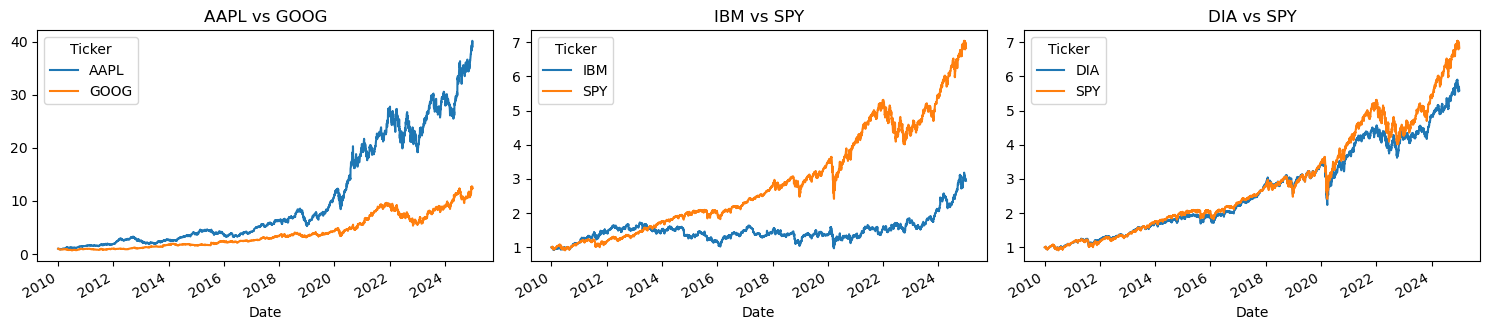

,ret_corr,EG_pvalue
pair,,
AAPL/GOOG,0.546,0.031
IBM/SPY,0.635,0.704
DIA/SPY,0.959,0.662


In [6]:
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import coint
fig, ax = plt.subplots(1, len(PAIRS), figsize=(5*len(PAIRS), 3.4))
rets_all = prices.pct_change().dropna()
rows = []
for a_, (x, y) in zip(ax, PAIRS):
    n = prices[[x, y]]/prices[[x, y]].iloc[0]
    n.plot(ax=a_, title=f"{x} vs {y}")
    rows.append(dict(pair=f"{x}/{y}", ret_corr=rets_all[x].corr(rets_all[y]),
                     EG_pvalue=coint(prices[y], prices[x])[1]))
plt.tight_layout(); plt.show()
pd.DataFrame(rows).set_index("pair").round(3)

## 3. Method code
### 3.1 Copula library
Five single copulas (Gaussian, Student-t, Clayton, Frank, Gumbel) and two mixtures (Clayton-Frank-Gumbel and Clayton-t-Gumbel, weights via softmax). Each class provides:
- `logc`: log copula density, used for maximum-likelihood fitting;
- `h(u1,u2) = dC/du2 = P(U1<=u1 | U2=u2)`: the conditional probability used as the **mispricing index** (Paper 1 eq. 10 / Paper 2 eq. 11-12 and Table 2).

`fit_copula` minimises the negative log-likelihood and also returns AIC/BIC. Paper 1 selects by raw log-likelihood (which mechanically favours the mixtures); Paper 2 uses AIC/BIC. The signal code records both.

In [7]:
class Gaussian:
    name = "Gaussian"; n = 1
    def tr(self, p): return (np.tanh(p[0]),)
    def x0(self): return [0.5]
    def logc(self, u1, u2, rho):
        x, y = stats.norm.ppf(u1), stats.norm.ppf(u2)
        return -0.5*np.log(1-rho**2) - (rho**2*(x**2+y**2) - 2*rho*x*y)/(2*(1-rho**2))
    def h(self, u1, u2, rho):
        x, y = stats.norm.ppf(u1), stats.norm.ppf(u2)
        return stats.norm.cdf((x-rho*y)/np.sqrt(1-rho**2))

class StudentT:
    name = "Student-t"; n = 2
    def tr(self, p): return (np.tanh(p[0]), 2.1 + 40*expit(p[1]))
    def x0(self): return [0.5, 0.0]
    def logc(self, u1, u2, rho, nu):
        x, y = stats.t.ppf(u1, nu), stats.t.ppf(u2, nu)
        q = (x**2 + y**2 - 2*rho*x*y)/(1-rho**2)
        from scipy.special import gammaln
        lj = (gammaln((nu+2)/2) - gammaln(nu/2) - np.log(nu*np.pi) - 0.5*np.log(1-rho**2)
              - (nu+2)/2*np.log1p(q/nu))
        return lj - stats.t.logpdf(x, nu) - stats.t.logpdf(y, nu)
    def h(self, u1, u2, rho, nu):
        x, y = stats.t.ppf(u1, nu), stats.t.ppf(u2, nu)
        return stats.t.cdf((x-rho*y)/np.sqrt((nu+y**2)*(1-rho**2)/(nu+1)), nu+1)

class Clayton:
    name = "Clayton"; n = 1
    def tr(self, p): return (0.05 + np.exp(p[0]),)
    def x0(self): return [0.0]
    def logc(self, u1, u2, th):
        s = u1**-th + u2**-th - 1
        return np.log1p(th) - (th+1)*np.log(u1*u2) - (2+1/th)*np.log(s)
    def h(self, u1, u2, th):
        return u2**(-th-1) * (u1**-th + u2**-th - 1)**(-1/th - 1)

class Gumbel:
    name = "Gumbel"; n = 1
    def tr(self, p): return (1.0 + 1e-3 + np.exp(p[0]),)
    def x0(self): return [-0.5]
    def logc(self, u1, u2, th):
        a, b = -np.log(u1), -np.log(u2); A = a**th + b**th
        return (-A**(1/th) - np.log(u1*u2) + (th-1)*np.log(a*b)
                + (2/th-2)*np.log(A) + np.log1p((th-1)*A**(-1/th)))
    def h(self, u1, u2, th):
        a, b = -np.log(u1), -np.log(u2); A = a**th + b**th
        return np.exp(-A**(1/th)) / u2 * b**(th-1) * A**(1/th-1)

class Frank:
    name = "Frank"; n = 1
    def tr(self, p): return (0.05 + np.exp(p[0]),)
    def x0(self): return [1.0]
    def logc(self, u1, u2, th):
        e = np.exp(-th)
        num = th*(1-e)*np.exp(-th*(u1+u2))
        den = ((1-e) - (1-np.exp(-th*u1))*(1-np.exp(-th*u2)))**2
        return np.log(num/den)
    def h(self, u1, u2, th):
        a, b = np.exp(-th*u1)-1, np.exp(-th*u2)-1
        return np.exp(-th*u2)*a/((np.exp(-th)-1) + a*b)

class Mixture:
    """Weighted sum of component copulas; weights via softmax."""
    def __init__(self, comps, name):
        self.c, self.name = comps, name
        self.n = len(comps)-1 + sum(c.n for c in comps)
    def split(self, p):
        k = len(self.c); w = np.exp(np.r_[0, p[:k-1]]); w /= w.sum()
        out, i = [], k-1
        for c in self.c:
            out.append(c.tr(p[i:i+c.n])); i += c.n
        return w, out
    def x0(self): return [0.0]*(len(self.c)-1) + [v for c in self.c for v in c.x0()]
    def tr(self, p): return (p,)
    def logc(self, u1, u2, p):
        w, ps = self.split(p)
        dens = sum(wi*np.exp(c.logc(u1, u2, *pi)) for wi, c, pi in zip(w, self.c, ps))
        return np.log(np.maximum(dens, 1e-300))
    def h(self, u1, u2, p):
        w, ps = self.split(p)
        return sum(wi*c.h(u1, u2, *pi) for wi, c, pi in zip(w, self.c, ps))

def make_models():
    C, F, G, T = Clayton(), Frank(), Gumbel(), StudentT()
    return [Gaussian(), C, F, G, T, Mixture([Clayton(), Frank(), Gumbel()], "Mixture CFG"),
            Mixture([Clayton(), StudentT(), Gumbel()], "Mixture CtG")]

def fit_copula(model, u1, u2, n_starts=3, seed=0):
    u1, u2 = clip(u1), clip(u2)
    def nll(p):
        try:
            v = -np.sum(model.logc(u1, u2, *model.tr(p)))
            return v if np.isfinite(v) else 1e10
        except Exception:
            return 1e10
    rng = np.random.default_rng(seed); x0 = np.array(model.x0(), float); best = None
    for k in range(n_starts if model.n > 2 else 1):
        s = x0 + (0 if k == 0 else rng.normal(0, 0.7, size=x0.size))
        r = optimize.minimize(nll, s, method="Nelder-Mead" if model.n <= 2 else "L-BFGS-B",
                              options={"maxiter": 600} if model.n <= 2 else {"maxiter": 200})
        if best is None or r.fun < best.fun: best = r
    k_par = model.n
    n = len(u1)
    return dict(model=model, params=model.tr(best.x), nll=best.fun,
                aic=2*best.fun + 2*k_par, bic=2*best.fun + k_par*np.log(n))

### 3.2 Marginals (ARMA-GARCH filter)
For each stock: fit AR(0 or 1)-GARCH(1,1) on the formation window (chosen by BIC), freeze the parameters, filter the trading window forward (no look-ahead), and convert standardised residuals to pseudo-observations in (0,1) with the formation-sample empirical CDF scaled by T/(T+1) (Paper 1, step 1).

In [8]:
def marginal_u(r_form, r_trade):
    """Fit on formation returns; return pseudo-observations for both windows."""
    from arch import arch_model
    y = 100*r_form.values; best = None
    for mean in ("Constant", "AR"):
        am = arch_model(y, mean=mean, lags=1 if mean == "AR" else 0, vol="GARCH", p=1, q=1, dist="normal")
        res = am.fit(disp="off")
        if best is None or res.bic < best[1].bic: best = (am, res, mean)
    am, res, mean = best
    z_form = res.std_resid[~np.isnan(res.std_resid)]
    full = np.r_[y, 100*r_trade.values]
    am2 = arch_model(full, mean=mean, lags=1 if mean == "AR" else 0, vol="GARCH", p=1, q=1)
    r2 = am2.fix(res.params.values)
    z_all = np.asarray(r2.std_resid)
    z_form_f, z_trade = z_all[:len(y)], z_all[len(y):]
    z_form_f = z_form_f[~np.isnan(z_form_f)]
    T = len(z_form_f)
    ecdf = lambda z: np.searchsorted(np.sort(z_form_f), z, side="right")/(T+1)
    u_form = clip(ecdf(z_all[:len(y)][~np.isnan(z_all[:len(y)])]))
    u_trade = clip(ecdf(np.nan_to_num(z_trade)))
    return u_form, u_trade, len(y)-len(u_form)

### 3.3 Trading signals
- **Distance** (Gatev et al.; Paper 1 sec 2.1): normalise prices to $1, open when the spread exceeds 2 formation-period standard deviations, close on crossing.
- **Cointegration** (Rad sec 4.2): Engle-Granger test on the formation window; if cointegrated (p<5%, beta>0) trade the standardised spread at +/-2, close at 0.
- **Copula** (Paper 1 steps 1-5 / Rad sec 4.3): fit all seven copulas, pick the best, compute daily MI for both stocks, accumulate into M1, M2, open a long-short when one exceeds +DELTA and the other is below -DELTA, close when both return to zero.

Position convention: `+1` = long first stock / short second; `-1` = the reverse.

In [9]:
def distance_signals(px_f, px_t, k=2.0):
    nf, nt = px_f/px_f.iloc[0], px_t/px_t.iloc[0]
    sd = (nf.iloc[:, 0]-nf.iloc[:, 1]).std()
    sp = (nt.iloc[:, 0]-nt.iloc[:, 1]).values
    pos, p = np.zeros(len(sp)), 0
    for t, s in enumerate(sp):
        if p == 0:
            if s > k*sd: p = -1          # X overpriced
            elif s < -k*sd: p = 1
        elif (p == -1 and s <= 0) or (p == 1 and s >= 0): p = 0
        pos[t] = p
    return pos, np.ones(len(sp)), np.ones(len(sp))

def coint_signals(px_f, px_t, k=2.0, alpha=0.05):
    from statsmodels.tsa.stattools import coint
    import statsmodels.api as sm
    nf, nt = px_f/px_f.iloc[0], px_t/px_t.iloc[0]
    x1, x2 = nf.iloc[:, 0], nf.iloc[:, 1]             # Rad: X2 - beta*X1 = u
    pval = coint(x2, x1)[1]
    ols = sm.OLS(x2, sm.add_constant(x1)).fit(); b = ols.params.iloc[1]
    if pval > alpha or b <= 0: return None
    spread_f = x2 - b*x1; mu, sd = spread_f.mean(), spread_f.std()
    z = ((nt.iloc[:, 1] - b*nt.iloc[:, 0]) - mu).values/sd
    pos, p = np.zeros(len(z)), 0
    for t, s in enumerate(z):
        if p == 0:
            if s > k: p = 1               # stock2 rich -> short stock2 (col 1), long stock1 (col 0): X=col0 long
            elif s < -k: p = -1
        elif (p == 1 and s <= 0) or (p == -1 and s >= 0): p = 0
        pos[t] = p
    # pos=+1 : long col0 (beta units), short col1 (1 unit) ; leg dollar weights below
    return pos, np.full(len(z), b), np.ones(len(z))

def copula_signals(ret_f, ret_t, delta=0.2, close_rule="both", models=None, verbose=False):
    models = models or make_models()
    uf1, ut1, d1 = marginal_u(ret_f.iloc[:, 0], ret_t.iloc[:, 0])
    uf2, ut2, d2 = marginal_u(ret_f.iloc[:, 1], ret_t.iloc[:, 1])
    m = min(len(uf1), len(uf2)); uf1, uf2 = uf1[-m:], uf2[-m:]
    fits = [fit_copula(mod, uf1, uf2) for mod in models]
    best = min(fits, key=lambda f: f["nll"])             # Paper 1 criterion (log-lik)
    best_bic = min(fits, key=lambda f: f["bic"])         # Paper 2 style (AIC/BIC)
    cop, par = best["model"], best["params"]
    ut1, ut2 = clip(ut1), clip(ut2)
    mi_xy = cop.h(ut1, ut2, *par)                         # P(U1<=u1|U2=u2) = dC/du2
    mi_yx = cop.h(ut2, ut1, *par)                         # P(U2<=u2|U1=u1) = dC/du1
    M1, M2 = np.cumsum(mi_xy-0.5), np.cumsum(mi_yx-0.5)
    pos, p = np.zeros(len(M1)), 0
    for t in range(len(M1)):
        if p == 0:
            if M1[t] > delta and M2[t] < -delta: p = -1  # X overvalued vs Y
            elif M1[t] < -delta and M2[t] > delta: p = 1
        else:
            if p == -1: done = (M1[t] <= 0 and M2[t] >= 0) if close_rule == "both" else (M1[t] <= 0 or M2[t] >= 0)
            else:       done = (M1[t] >= 0 and M2[t] <= 0) if close_rule == "both" else (M1[t] >= 0 or M2[t] <= 0)
            if done: p = 0
        pos[t] = p
    info = dict(best_ll=cop.name, best_bic=best_bic["model"].name, fits={f["model"].name: f["nll"] for f in fits})
    return pos, np.ones(len(pos)), np.ones(len(pos)), info

### 3.4 PnL engine (Rad et al. sec 4.4-4.5; Paper 1 eq. 1)
Each trade is $1 long and $1 short; the dollar value of each leg then drifts with its stock's return (Paper 1 eq. 1). A signal at the close of day *t* is acted on at the close of *t+LAG* and earns from the next day. The round-trip cost (default 20 bps) is charged half on entry and half on exit. Returns are reported two ways:
- **Committed capital:** daily PnL summed over pairs divided by the number of pairs nominated (3).
- **Fully invested / employed capital:** PnL summed over pairs divided by the number of pairs open that day.

In [10]:
def pair_pnl(pos, rX, rY, wX=None, wY=None, cost_rt=0.0020, lag=0):
    """Position signal at close of day t is acted at close of t+lag, earns from t+lag+1."""
    n = len(pos); pnl = np.zeros(n); open_flag = np.zeros(n, bool)
    eff = np.r_[np.zeros(lag), pos[:n-lag]] if lag else pos
    prev, LX, LY = 0, 1.0, 1.0
    for t in range(n):
        # eff[t] is the position held at the close of day t; it earns on day t+1
        if t+1 < n:
            p = eff[t]
            if p != prev:
                c = (abs(p) + abs(prev)) * cost_rt/2.0            # half a round trip per leg-pair change
                pnl[t] -= c
                if p != 0: LX = LY = 1.0                           # fresh $1/$1
            if p != 0:
                # +1 long X short Y;  -1 short X long Y  (unit dollar legs, Eq.1 weights evolve)
                sx = p
                pnl[t+1] += sx*LX*rX[t+1] - sx*LY*rY[t+1]
                LX *= 1+rX[t+1]; LY *= 1+rY[t+1]
                open_flag[t+1] = True
            prev = p
    return pnl, open_flag

### 3.5 Walk-forward driver
Rolls a 12-month formation window and a 6-month trading window forward every 6 months, applies the chosen method to each pair, and aggregates daily PnL into committed- and fully-invested-capital series.

In [11]:
def ssd(px_f, a, b):
    n = px_f/px_f.iloc[0]
    return ((n[a]-n[b])**2).sum()

def run_strategy(prices, pairs, method, form=252, trade=126, top_n=None, delta=0.2,
                 cost_rt=0.0020, lag=0, close_rule="both", verbose=True):
    rets = prices.pct_change().dropna(); prices = prices.loc[rets.index]
    if top_n is not None and len(pairs) > top_n:
        pass  # ranking is done per window below
    pnl_c, pnl_e, ntr, logs = [], [], [], []
    start = form
    while start + trade <= len(prices):
        pf, pt = prices.iloc[start-form:start], prices.iloc[start:start+trade]
        rf, rt = rets.iloc[start-form:start], rets.iloc[start:start+trade]
        win = pairs
        if top_n is not None and len(pairs) > top_n:
            win = sorted(pairs, key=lambda p: ssd(pf, *p))[:top_n]
        daily, flags = [], []
        for a, b in win:
            try:
                if method == "distance":
                    pos, wx, wy = distance_signals(pf[[a, b]], pt[[a, b]])
                    pnl, fl = pair_pnl(pos, rt[a].values, rt[b].values, cost_rt=cost_rt, lag=lag)
                elif method == "cointegration":
                    out = coint_signals(pf[[a, b]], pt[[a, b]])
                    if out is None: pnl, fl = np.zeros(len(pt)), np.zeros(len(pt), bool)
                    else:
                        pos, wx, wy = out
                        pnl, fl = pair_pnl(pos, rt[a].values, rt[b].values, cost_rt=cost_rt, lag=lag)
                elif method.startswith("copula"):
                    pos, wx, wy, info = copula_signals(rf[[a, b]], rt[[a, b]], delta=delta, close_rule=close_rule)
                    pnl, fl = pair_pnl(pos, rt[a].values, rt[b].values, cost_rt=cost_rt, lag=lag)
                    logs.append(dict(window=pt.index[0].date(), pair=f"{a}/{b}", **{k: v for k, v in info.items() if k != "fits"}))
                else:
                    raise ValueError(method)
            except Exception as e:
                if verbose: print("  skip", a, b, repr(e)[:80])
                pnl, fl = np.zeros(len(pt)), np.zeros(len(pt), bool)
            daily.append(pnl); flags.append(fl)
        D, F = np.array(daily), np.array(flags)
        idx = pt.index
        pnl_c.append(pd.Series(D.sum(0)/len(win), idx))                            # committed capital
        nopen = F.sum(0)
        pnl_e.append(pd.Series(np.where(nopen > 0, D.sum(0)/np.maximum(nopen, 1), 0.0), idx))  # fully invested
        start += trade
        if verbose: print(f"  {method:14s} window ending {idx[-1].date()} done")
    return pd.concat(pnl_c), pd.concat(pnl_e), pd.DataFrame(logs)

### 3.6 Performance statistics
Annualised mean/volatility, Sharpe, Sortino (downside deviation with 0% target), maximum drawdown, Newey-West t-statistic (6 lags), share of negative days, min/max day.

In [12]:
def perf(r, name=""):
    import statsmodels.api as sm
    r = r.dropna(); mu, sd = r.mean()*252, r.std()*np.sqrt(252)
    dd = np.sqrt((np.minimum(r, 0)**2).mean())*np.sqrt(252)
    eq = (1+r).cumprod(); mdd = (1-eq/eq.cummax()).max()
    nw = sm.OLS(r.values, np.ones(len(r))).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    return pd.Series(dict(ann_ret_pct=100*mu, ann_vol_pct=100*sd, sharpe=mu/sd if sd else np.nan,
                          sortino=mu/dd if dd else np.nan, max_dd_pct=100*mdd,
                          nw_tstat=float(nw.tvalues[0]), pct_neg_days=100*(r < 0).mean(),
                          min_day_pct=100*r.min(), max_day_pct=100*r.max()), name=name)

def ff_alpha(r, ff):
    """Optional: regress on Fama-French factors (daily, in decimals) from Ken French's library."""
    import statsmodels.api as sm
    d = pd.concat([r, ff], axis=1, join="inner").dropna()
    y = d.iloc[:, 0] - d["RF"]; X = sm.add_constant(d.drop(columns=[d.columns[0], "RF"]))
    return sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})

## 4. Run the strategies
This is the slow cell (ARMA-GARCH and 7 copula fits per pair per window). Distance and cointegration are fast.

In [13]:
results = {}
for m in ["distance", "cointegration", "copula"]:
    c, e, lg = run_strategy(prices, PAIRS, m, form=FORM, trade=TRADE, delta=DELTA,
                            cost_rt=COST_BPS/1e4, lag=LAG, verbose=False)
    results[m] = dict(committed=c, invested=e, log=lg)
    print(m, "done:", len(c), "days")

distance done: 3402 days
cointegration done: 3402 days
copula done: 3402 days


## 5. Analysis
### 5.1 Performance tables (after costs)
Compare with Paper 1 Table 1 and Paper 2 Table 3 for the *direction* of the results, not the exact numbers: the papers use hundreds of pairs, this uses three.

In [14]:
pd.set_option("display.width", 200)
tab_c = pd.DataFrame({m: perf(r["committed"], m) for m, r in results.items()}).T
tab_e = pd.DataFrame({m: perf(r["invested"], m) for m, r in results.items()}).T
print("COMMITTED CAPITAL"); display(tab_c.round(3))
print("FULLY INVESTED CAPITAL"); display(tab_e.round(3))

COMMITTED CAPITAL


,ann_ret_pct,ann_vol_pct,sharpe,sortino,max_dd_pct,nw_tstat,pct_neg_days,min_day_pct,max_day_pct
distance,-0.424,5.657,-0.075,-0.106,29.550,-0.271,28.513,-3.627,3.852
cointegration,-0.146,0.970,-0.150,-0.208,4.940,-0.538,3.351,-1.345,1.342
copula,-4.527,10.124,-0.447,-0.619,54.808,-1.606,51.969,-5.684,4.629


FULLY INVESTED CAPITAL


,ann_ret_pct,ann_vol_pct,sharpe,sortino,max_dd_pct,nw_tstat,pct_neg_days,min_day_pct,max_day_pct
distance,-1.754,11.039,-0.159,-0.218,51.272,-0.560,27.748,-8.023,6.731
cointegration,-0.072,1.724,-0.042,-0.062,8.246,-0.142,3.263,-2.017,2.249
copula,-5.999,12.044,-0.498,-0.647,63.904,-1.753,51.058,-17.052,5.399


(3773, 5) 2010-01-04 -> 2024-12-30


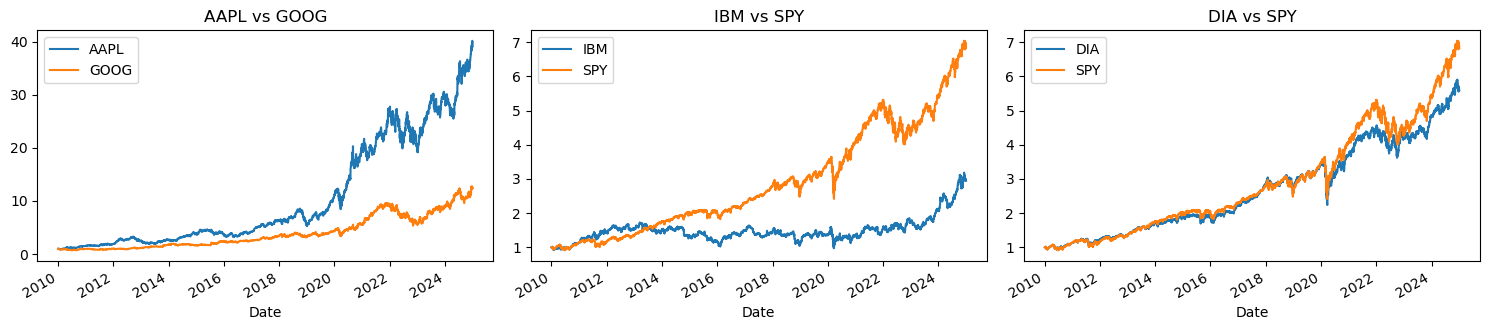

distance done: 3402 days
cointegration done: 3402 days
copula done: 3402 days
AAPL/GOOG: formation 2010-01-05 -> 2011-01-03 (252 days), trading 2011-01-04 -> 2011-07-05 (126 days)
Formation-period SSD of normalised prices: 38.9702


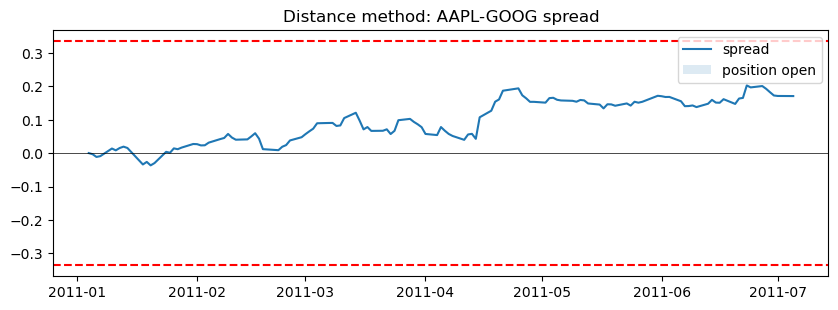

Position changes: 0 | window PnL per $1 leg: 0.0
Engle-Granger p-value 0.404, beta 0.152 -> pair is NOT traded by the cointegration method this window
Position changes: 0


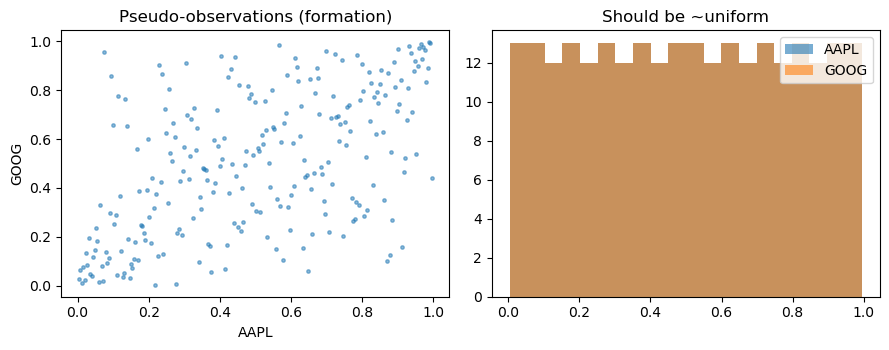

Rank (Kendall) correlation of the pseudo-observations: 0.392


,n_params,neg_loglik,AIC,BIC
copula,,,,
Gaussian,1,-54.6,-107.2,-103.6
Clayton,1,-49.1,-96.1,-92.6
Frank,1,-47.3,-92.5,-89.0
Gumbel,1,-54.1,-106.2,-102.7
Student-t,2,-60.2,-116.3,-109.3
Mixture CFG,5,-60.8,-111.6,-94.0
Mixture CtG,6,-63.5,-114.9,-93.8


Best by log-likelihood: Mixture CtG | best by AIC: Student-t | best by BIC: Student-t


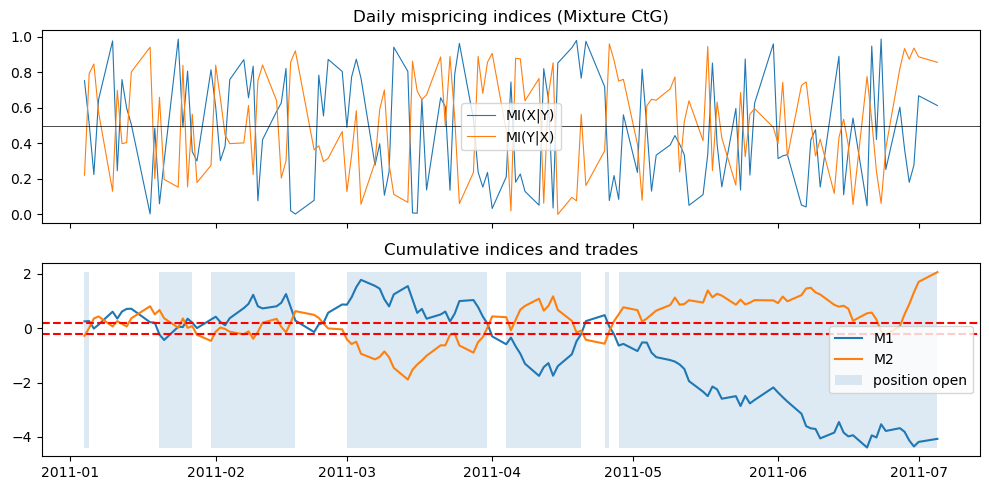

,date,"new_position(+1 long a/short b, -1 reverse, 0 flat)"
0,2011-01-04,-1
1,2011-01-06,0
2,2011-01-20,1
3,2011-01-28,0
4,2011-01-31,-1
5,2011-02-22,0
6,2011-03-01,-1
7,2011-04-01,0
8,2011-04-04,1
9,2011-04-21,0


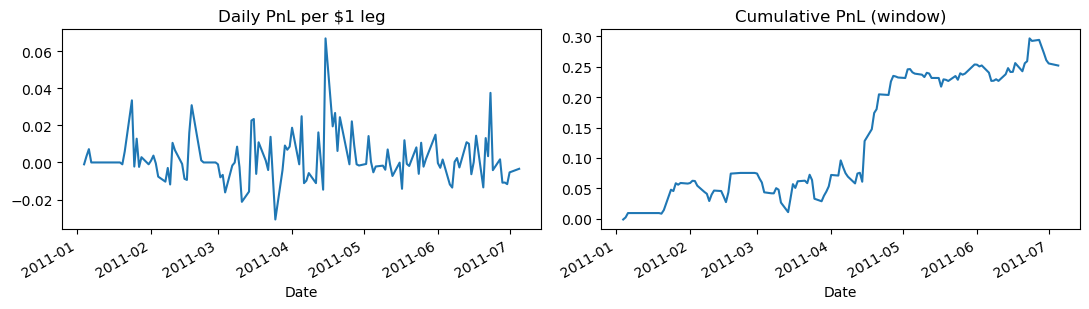

Days in market: 107 | window PnL: 0.2518 | trades opened: 7
COMMITTED CAPITAL


,ann_ret_pct,ann_vol_pct,sharpe,sortino,max_dd_pct,nw_tstat,pct_neg_days,min_day_pct,max_day_pct
distance,-0.424,5.657,-0.075,-0.106,29.550,-0.271,28.513,-3.627,3.852
cointegration,-0.146,0.970,-0.150,-0.208,4.940,-0.538,3.351,-1.345,1.342
copula,-4.475,10.121,-0.442,-0.612,54.489,-1.588,51.940,-5.684,4.629


FULLY INVESTED CAPITAL


,ann_ret_pct,ann_vol_pct,sharpe,sortino,max_dd_pct,nw_tstat,pct_neg_days,min_day_pct,max_day_pct
distance,-1.754,11.039,-0.159,-0.218,51.272,-0.560,27.748,-8.023,6.731
cointegration,-0.072,1.724,-0.042,-0.062,8.246,-0.142,3.263,-2.017,2.249
copula,-5.826,12.031,-0.484,-0.630,63.044,-1.706,51.029,-17.052,5.399


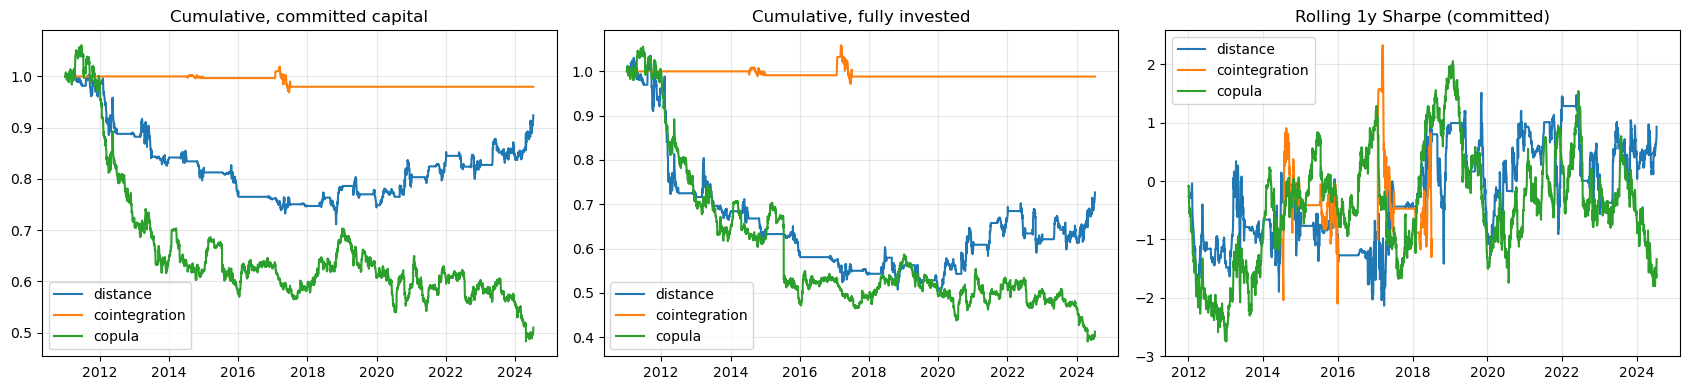

Pairs-windows fitted: 81


,log-likelihood,BIC
Mixture CtG,79.0,7.4
Mixture CFG,19.8,0.0
Student-t,1.2,51.9
Clayton,0.0,14.8
Gaussian,0.0,14.8
Frank,0.0,9.9
Gumbel,0.0,1.2


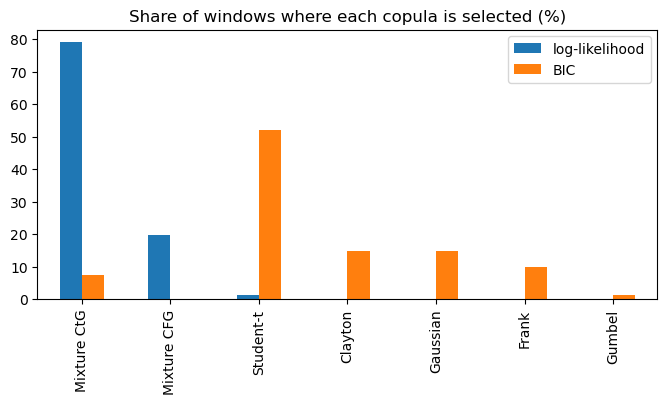

best_ll,Mixture CFG,Mixture CtG,Student-t
pair,,,
AAPL/GOOG,7,20,0
DIA/SPY,0,27,0
IBM/SPY,9,17,1


,trades_opened,avg_days_open,pct_time_in_market
distance,51.0,56.51,27.29
cointegration,5.0,59.00,2.79
copula,231.0,40.26,88.06


,alpha_%/day,alpha_t,beta_mkt,t_mkt,beta_mom,t_mom,adj_R2
distance,-0.0049,-0.7977,-0.0043,-0.6447,-0.0526,-6.5889,0.0339
cointegration,-0.0048,-4.3179,-0.0004,-0.7157,-0.0018,-1.5895,-0.0002
copula,-0.0211,-1.9101,-0.0026,-0.1756,-0.0025,-0.1563,0.0054


,observed,p_value
mean return diff (ann.),-0.0405,0.1560
Sharpe diff,-0.3673,0.2685


In [22]:

try:
    display
except NameError:          # running as a plain .py script
    display = print





USE_SYNTHETIC = False            # True = simulated data, False = download real data
START, END    = "2010-01-01", "2024-12-31"
PAIRS         = [("AAPL", "GOOG"), ("IBM", "SPY"), ("DIA", "SPY")]
FORM, TRADE   = 252, 126         # formation (12m) and trading (6m) windows in trading days
DELTA         = 0.2              # copula opening threshold on cumulative mispricing indices (Paper 1)
COST_BPS      = 20               # round-trip cost per pair trade (Paper 1: 20 bps)
LAG           = 0                # 0 = trade at signal close (as in the papers); 1 = next-day execution
RUN_ROBUSTNESS = False           # execution-lag and threshold sensitivity (slower)

import warnings, numpy as np, pandas as pd
from scipy import stats, optimize
from scipy.special import expit
from itertools import combinations
warnings.filterwarnings("ignore")
EPS = 1e-6
clip = lambda u: np.clip(u, EPS, 1 - EPS)



def load_prices(tickers, start, end):
    import yfinance as yf
    px = yf.download(tickers, start=start, end=end, auto_adjust=True, progress=False)["Close"]
    return px.dropna()

def synthetic_prices(n=2520, seed=1):
    """Offline test data with fat tails/GARCH. SPY shared by IBM/SPY and DIA/SPY."""
    rng = np.random.default_rng(seed); idx = pd.bdate_range("2012-01-02", periods=n)
    def garch(s0):
        e, h = np.zeros(n), np.full(n, s0**2)
        for t in range(1, n):
            h[t] = 1e-6 + 0.08*e[t-1]**2 + 0.90*h[t-1]
            e[t] = np.sqrt(h[t])*rng.standard_t(5)/np.sqrt(5/3)
        return e
    def ou(kappa, sig):
        s = np.zeros(n)
        for t in range(1, n): s[t] = (1-kappa)*s[t-1] + sig*rng.standard_normal()
        return s
    spy = np.cumsum(garch(0.01) + 0.0004)
    aapl = np.cumsum(garch(0.014)) + 0.4*spy
    return pd.DataFrame({"SPY": 100*np.exp(spy), "DIA": 100*np.exp(spy + ou(0.15, 0.003)),
                         "IBM": 100*np.exp(0.7*spy + np.cumsum(garch(0.008)) + ou(0.05, 0.008)),
                         "AAPL": 100*np.exp(aapl), "GOOG": 100*np.exp(aapl + ou(0.03, 0.012))}, index=idx)

import os
if USE_SYNTHETIC:
    prices = synthetic_prices()
else:
    tickers = sorted({t for p in PAIRS for t in p})
    if os.path.exists("prices.csv"):
        prices = pd.read_csv("prices.csv", index_col=0, parse_dates=True)
    else:
        prices = load_prices(tickers, START, END)
        prices.to_csv("prices.csv")
prices = prices[sorted({t for p in PAIRS for t in p})].dropna()
print(prices.shape, prices.index[0].date(), "->", prices.index[-1].date())
prices.tail()




import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import coint
fig, ax = plt.subplots(1, len(PAIRS), figsize=(5*len(PAIRS), 3.4))
rets_all = prices.pct_change().dropna()
rows = []
for a_, (x, y) in zip(ax, PAIRS):
    n = prices[[x, y]]/prices[[x, y]].iloc[0]
    n.plot(ax=a_, title=f"{x} vs {y}")
    rows.append(dict(pair=f"{x}/{y}", ret_corr=rets_all[x].corr(rets_all[y]),
                     EG_pvalue=coint(prices[y], prices[x])[1]))
plt.tight_layout(); plt.show()
pd.DataFrame(rows).set_index("pair").round(3)




class Gaussian:
    name = "Gaussian"; n = 1
    def tr(self, p): return (np.tanh(p[0]),)
    def x0(self): return [0.5]
    def logc(self, u1, u2, rho):
        x, y = stats.norm.ppf(u1), stats.norm.ppf(u2)
        return -0.5*np.log(1-rho**2) - (rho**2*(x**2+y**2) - 2*rho*x*y)/(2*(1-rho**2))
    def h(self, u1, u2, rho):
        x, y = stats.norm.ppf(u1), stats.norm.ppf(u2)
        return stats.norm.cdf((x-rho*y)/np.sqrt(1-rho**2))

class StudentT:
    name = "Student-t"; n = 2
    def tr(self, p): return (np.tanh(p[0]), 2.1 + 40*expit(p[1]))
    def x0(self): return [0.5, 0.0]
    def logc(self, u1, u2, rho, nu):
        x, y = stats.t.ppf(u1, nu), stats.t.ppf(u2, nu)
        q = (x**2 + y**2 - 2*rho*x*y)/(1-rho**2)
        from scipy.special import gammaln
        lj = (gammaln((nu+2)/2) - gammaln(nu/2) - np.log(nu*np.pi) - 0.5*np.log(1-rho**2)
              - (nu+2)/2*np.log1p(q/nu))
        return lj - stats.t.logpdf(x, nu) - stats.t.logpdf(y, nu)
    def h(self, u1, u2, rho, nu):
        x, y = stats.t.ppf(u1, nu), stats.t.ppf(u2, nu)
        return stats.t.cdf((x-rho*y)/np.sqrt((nu+y**2)*(1-rho**2)/(nu+1)), nu+1)

class Clayton:
    name = "Clayton"; n = 1
    def tr(self, p): return (0.05 + np.exp(p[0]),)
    def x0(self): return [0.0]
    def logc(self, u1, u2, th):
        s = u1**-th + u2**-th - 1
        return np.log1p(th) - (th+1)*np.log(u1*u2) - (2+1/th)*np.log(s)
    def h(self, u1, u2, th):
        return u2**(-th-1) * (u1**-th + u2**-th - 1)**(-1/th - 1)

class Gumbel:
    name = "Gumbel"; n = 1
    def tr(self, p): return (1.0 + 1e-3 + np.exp(p[0]),)
    def x0(self): return [-0.5]
    def logc(self, u1, u2, th):
        a, b = -np.log(u1), -np.log(u2); A = a**th + b**th
        return (-A**(1/th) - np.log(u1*u2) + (th-1)*np.log(a*b)
                + (2/th-2)*np.log(A) + np.log1p((th-1)*A**(-1/th)))
    def h(self, u1, u2, th):
        a, b = -np.log(u1), -np.log(u2); A = a**th + b**th
        return np.exp(-A**(1/th)) / u2 * b**(th-1) * A**(1/th-1)

class Frank:
    name = "Frank"; n = 1
    def tr(self, p): return (0.05 + np.exp(p[0]),)
    def x0(self): return [1.0]
    def logc(self, u1, u2, th):
        e = np.exp(-th)
        num = th*(1-e)*np.exp(-th*(u1+u2))
        den = ((1-e) - (1-np.exp(-th*u1))*(1-np.exp(-th*u2)))**2
        return np.log(num/den)
    def h(self, u1, u2, th):
        a, b = np.exp(-th*u1)-1, np.exp(-th*u2)-1
        return np.exp(-th*u2)*a/((np.exp(-th)-1) + a*b)

class Mixture:
    """Weighted sum of component copulas; weights via softmax."""
    def __init__(self, comps, name):
        self.c, self.name = comps, name
        self.n = len(comps)-1 + sum(c.n for c in comps)
    def split(self, p):
        k = len(self.c); w = np.exp(np.r_[0, p[:k-1]]); w /= w.sum()
        out, i = [], k-1
        for c in self.c:
            out.append(c.tr(p[i:i+c.n])); i += c.n
        return w, out
    def x0(self): return [0.0]*(len(self.c)-1) + [v for c in self.c for v in c.x0()]
    def tr(self, p): return (p,)
    def logc(self, u1, u2, p):
        w, ps = self.split(p)
        dens = sum(wi*np.exp(c.logc(u1, u2, *pi)) for wi, c, pi in zip(w, self.c, ps))
        return np.log(np.maximum(dens, 1e-300))
    def h(self, u1, u2, p):
        w, ps = self.split(p)
        return sum(wi*c.h(u1, u2, *pi) for wi, c, pi in zip(w, self.c, ps))

def make_models():
    C, F, G, T = Clayton(), Frank(), Gumbel(), StudentT()
    return [Gaussian(), C, F, G, T, Mixture([Clayton(), Frank(), Gumbel()], "Mixture CFG"),
            Mixture([Clayton(), StudentT(), Gumbel()], "Mixture CtG")]

def fit_copula(model, u1, u2, n_starts=3, seed=0):
    u1, u2 = clip(u1), clip(u2)
    def nll(p):
        try:
            v = -np.sum(model.logc(u1, u2, *model.tr(p)))
            return v if np.isfinite(v) else 1e10
        except Exception:
            return 1e10
    rng = np.random.default_rng(seed); x0 = np.array(model.x0(), float); best = None
    for k in range(n_starts if model.n > 2 else 1):
        s = x0 + (0 if k == 0 else rng.normal(0, 0.7, size=x0.size))
        r = optimize.minimize(nll, s, method="Nelder-Mead" if model.n <= 2 else "L-BFGS-B",
                              options={"maxiter": 600} if model.n <= 2 else {"maxiter": 200})
        if best is None or r.fun < best.fun: best = r
    k_par = model.n
    n = len(u1)
    return dict(model=model, params=model.tr(best.x), nll=best.fun,
                aic=2*best.fun + 2*k_par, bic=2*best.fun + k_par*np.log(n))



def marginal_u(r_form, r_trade):
    """Fit on formation returns; return pseudo-observations for both windows."""
    from arch import arch_model
    y = 100*r_form.values; best = None
    for mean in ("Constant", "AR"):
        am = arch_model(y, mean=mean, lags=1 if mean == "AR" else 0, vol="GARCH", p=1, q=1, dist="normal")
        res = am.fit(disp="off")
        if best is None or res.bic < best[1].bic: best = (am, res, mean)
    am, res, mean = best
    z_form = res.std_resid[~np.isnan(res.std_resid)]
    full = np.r_[y, 100*r_trade.values]
    am2 = arch_model(full, mean=mean, lags=1 if mean == "AR" else 0, vol="GARCH", p=1, q=1)
    r2 = am2.fix(res.params.values)
    z_all = np.asarray(r2.std_resid)
    z_form_f, z_trade = z_all[:len(y)], z_all[len(y):]
    z_form_f = z_form_f[~np.isnan(z_form_f)]
    T = len(z_form_f)
    ecdf = lambda z: np.searchsorted(np.sort(z_form_f), z, side="right")/(T+1)
    u_form = clip(ecdf(z_all[:len(y)][~np.isnan(z_all[:len(y)])]))
    u_trade = clip(ecdf(np.nan_to_num(z_trade)))
    return u_form, u_trade, len(y)-len(u_form)




def distance_signals(px_f, px_t, k=2.0):
    nf, nt = px_f/px_f.iloc[0], px_t/px_t.iloc[0]
    sd = (nf.iloc[:, 0]-nf.iloc[:, 1]).std()
    sp = (nt.iloc[:, 0]-nt.iloc[:, 1]).values
    pos, p = np.zeros(len(sp)), 0
    for t, s in enumerate(sp):
        if p == 0:
            if s > k*sd: p = -1          # X overpriced
            elif s < -k*sd: p = 1
        elif (p == -1 and s <= 0) or (p == 1 and s >= 0): p = 0
        pos[t] = p
    return pos, np.ones(len(sp)), np.ones(len(sp))

def coint_signals(px_f, px_t, k=2.0, alpha=0.05):
    from statsmodels.tsa.stattools import coint
    import statsmodels.api as sm
    nf, nt = px_f/px_f.iloc[0], px_t/px_t.iloc[0]
    x1, x2 = nf.iloc[:, 0], nf.iloc[:, 1]             # Rad: X2 - beta*X1 = u
    pval = coint(x2, x1)[1]
    ols = sm.OLS(x2, sm.add_constant(x1)).fit(); b = ols.params.iloc[1]
    if pval > alpha or b <= 0: return None
    spread_f = x2 - b*x1; mu, sd = spread_f.mean(), spread_f.std()
    z = ((nt.iloc[:, 1] - b*nt.iloc[:, 0]) - mu).values/sd
    pos, p = np.zeros(len(z)), 0
    for t, s in enumerate(z):
        if p == 0:
            if s > k: p = 1               # stock2 rich -> short stock2 (col 1), long stock1 (col 0): X=col0 long
            elif s < -k: p = -1
        elif (p == 1 and s <= 0) or (p == -1 and s >= 0): p = 0
        pos[t] = p
    # pos=+1 : long col0 (beta units), short col1 (1 unit) ; leg dollar weights below
    return pos, np.full(len(z), b), np.ones(len(z))

def copula_signals(ret_f, ret_t, delta=0.2, close_rule="both", models=None, verbose=False):
    models = models or make_models()
    uf1, ut1, d1 = marginal_u(ret_f.iloc[:, 0], ret_t.iloc[:, 0])
    uf2, ut2, d2 = marginal_u(ret_f.iloc[:, 1], ret_t.iloc[:, 1])
    m = min(len(uf1), len(uf2)); uf1, uf2 = uf1[-m:], uf2[-m:]
    fits = [fit_copula(mod, uf1, uf2) for mod in models]
    best = min(fits, key=lambda f: f["nll"])             # Paper 1 criterion (log-lik)
    best_bic = min(fits, key=lambda f: f["bic"])         # Paper 2 style (AIC/BIC)
    cop, par = best["model"], best["params"]
    ut1, ut2 = clip(ut1), clip(ut2)
    mi_xy = cop.h(ut1, ut2, *par)                         # P(U1<=u1|U2=u2) = dC/du2
    mi_yx = cop.h(ut2, ut1, *par)                         # P(U2<=u2|U1=u1) = dC/du1
    M1, M2 = np.cumsum(mi_xy-0.5), np.cumsum(mi_yx-0.5)
    pos, p = np.zeros(len(M1)), 0
    for t in range(len(M1)):
        if p == 0:
            if M1[t] > delta and M2[t] < -delta: p = -1  # X overvalued vs Y
            elif M1[t] < -delta and M2[t] > delta: p = 1
        else:
            if p == -1: done = (M1[t] <= 0 and M2[t] >= 0) if close_rule == "both" else (M1[t] <= 0 or M2[t] >= 0)
            else:       done = (M1[t] >= 0 and M2[t] <= 0) if close_rule == "both" else (M1[t] >= 0 or M2[t] <= 0)
            if done: p = 0
        pos[t] = p
    info = dict(best_ll=cop.name, best_bic=best_bic["model"].name, fits={f["model"].name: f["nll"] for f in fits})
    return pos, np.ones(len(pos)), np.ones(len(pos)), info




def pair_pnl(pos, rX, rY, wX=None, wY=None, cost_rt=0.0020, lag=0):
    """Position signal at close of day t is acted at close of t+lag, earns from t+lag+1."""
    n = len(pos); pnl = np.zeros(n); open_flag = np.zeros(n, bool)
    eff = np.r_[np.zeros(lag), pos[:n-lag]] if lag else pos
    prev, LX, LY = 0, 1.0, 1.0
    for t in range(n):
        # eff[t] is the position held at the close of day t; it earns on day t+1
        if t+1 < n:
            p = eff[t]
            if p != prev:
                c = (abs(p) + abs(prev)) * cost_rt/2.0            # half a round trip per leg-pair change
                pnl[t] -= c
                if p != 0: LX = LY = 1.0                           # fresh $1/$1
            if p != 0:
                # +1 long X short Y;  -1 short X long Y  (unit dollar legs, Eq.1 weights evolve)
                sx = p
                pnl[t+1] += sx*LX*rX[t+1] - sx*LY*rY[t+1]
                LX *= 1+rX[t+1]; LY *= 1+rY[t+1]
                open_flag[t+1] = True
            prev = p
    return pnl, open_flag



def ssd(px_f, a, b):
    n = px_f/px_f.iloc[0]
    return ((n[a]-n[b])**2).sum()

def run_strategy(prices, pairs, method, form=252, trade=126, top_n=None, delta=0.2,
                 cost_rt=0.0020, lag=0, close_rule="both", verbose=True):
    rets = prices.pct_change().dropna(); prices = prices.loc[rets.index]
    if top_n is not None and len(pairs) > top_n:
        pass  # ranking is done per window below
    pnl_c, pnl_e, ntr, logs = [], [], [], []
    start = form
    while start + trade <= len(prices):
        pf, pt = prices.iloc[start-form:start], prices.iloc[start:start+trade]
        rf, rt = rets.iloc[start-form:start], rets.iloc[start:start+trade]
        win = pairs
        if top_n is not None and len(pairs) > top_n:
            win = sorted(pairs, key=lambda p: ssd(pf, *p))[:top_n]
        daily, flags = [], []
        for a, b in win:
            try:
                if method == "distance":
                    pos, wx, wy = distance_signals(pf[[a, b]], pt[[a, b]])
                    pnl, fl = pair_pnl(pos, rt[a].values, rt[b].values, cost_rt=cost_rt, lag=lag)
                elif method == "cointegration":
                    out = coint_signals(pf[[a, b]], pt[[a, b]])
                    if out is None: pnl, fl = np.zeros(len(pt)), np.zeros(len(pt), bool)
                    else:
                        pos, wx, wy = out
                        pnl, fl = pair_pnl(pos, rt[a].values, rt[b].values, cost_rt=cost_rt, lag=lag)
                elif method.startswith("copula"):
                    pos, wx, wy, info = copula_signals(rf[[a, b]], rt[[a, b]], delta=delta, close_rule=close_rule)
                    pnl, fl = pair_pnl(pos, rt[a].values, rt[b].values, cost_rt=cost_rt, lag=lag)
                    logs.append(dict(window=pt.index[0].date(), pair=f"{a}/{b}", **{k: v for k, v in info.items() if k != "fits"}))
                else:
                    raise ValueError(method)
            except Exception as e:
                if verbose: print("  skip", a, b, repr(e)[:80])
                pnl, fl = np.zeros(len(pt)), np.zeros(len(pt), bool)
            daily.append(pnl); flags.append(fl)
        D, F = np.array(daily), np.array(flags)
        idx = pt.index
        pnl_c.append(pd.Series(D.sum(0)/len(win), idx))                            # committed capital
        nopen = F.sum(0)
        pnl_e.append(pd.Series(np.where(nopen > 0, D.sum(0)/np.maximum(nopen, 1), 0.0), idx))  # fully invested
        start += trade
        if verbose: print(f"  {method:14s} window ending {idx[-1].date()} done")
    return pd.concat(pnl_c), pd.concat(pnl_e), pd.DataFrame(logs)




def perf(r, name=""):
    import statsmodels.api as sm
    r = r.dropna(); mu, sd = r.mean()*252, r.std()*np.sqrt(252)
    dd = np.sqrt((np.minimum(r, 0)**2).mean())*np.sqrt(252)
    eq = (1+r).cumprod(); mdd = (1-eq/eq.cummax()).max()
    nw = sm.OLS(r.values, np.ones(len(r))).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    return pd.Series(dict(ann_ret_pct=100*mu, ann_vol_pct=100*sd, sharpe=mu/sd if sd else np.nan,
                          sortino=mu/dd if dd else np.nan, max_dd_pct=100*mdd,
                          nw_tstat=float(nw.tvalues[0]), pct_neg_days=100*(r < 0).mean(),
                          min_day_pct=100*r.min(), max_day_pct=100*r.max()), name=name)

def ff_alpha(r, ff):
    """Optional: regress on Fama-French factors (daily, in decimals) from Ken French's library."""
    import statsmodels.api as sm
    d = pd.concat([r, ff], axis=1, join="inner").dropna()
    y = d.iloc[:, 0] - d["RF"]; X = sm.add_constant(d.drop(columns=[d.columns[0], "RF"]))
    return sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})




results = {}
for m in ["distance", "cointegration", "copula"]:
    c, e, lg = run_strategy(prices, PAIRS, m, form=FORM, trade=TRADE, delta=DELTA,
                            cost_rt=COST_BPS/1e4, lag=LAG, verbose=False)
    results[m] = dict(committed=c, invested=e, log=lg)
    print(m, "done:", len(c), "days")



PAIR_I, WINDOW = 0, 0            # which pair in PAIRS, which 6-month window (0 = first)
a, b = PAIRS[PAIR_I]
rets_w = prices.pct_change().dropna(); px_w = prices.loc[rets_w.index]
s0 = FORM + WINDOW*TRADE
pf, pt = px_w.iloc[s0-FORM:s0], px_w.iloc[s0:s0+TRADE]
rf, rt = rets_w.iloc[s0-FORM:s0], rets_w.iloc[s0:s0+TRADE]
print(f"{a}/{b}: formation {pf.index[0].date()} -> {pf.index[-1].date()} ({len(pf)} days), "
      f"trading {pt.index[0].date()} -> {pt.index[-1].date()} ({len(pt)} days)")
print("Formation-period SSD of normalised prices:", round(ssd(pf, a, b), 4))



pos_d, _, _ = distance_signals(pf[[a, b]], pt[[a, b]])
nf = pf[[a, b]]/pf[[a, b]].iloc[0]; nt = pt[[a, b]]/pt[[a, b]].iloc[0]
sd = (nf[a]-nf[b]).std(); spr = nt[a]-nt[b]
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(spr, label="spread"); ax.axhline(2*sd, ls="--", c="r"); ax.axhline(-2*sd, ls="--", c="r"); ax.axhline(0, c="k", lw=.5)
ax.fill_between(spr.index, spr.min(), spr.max(), where=pos_d != 0, alpha=.15, label="position open")
ax.set_title(f"Distance method: {a}-{b} spread"); ax.legend(); plt.show()
pnl_d, fl_d = pair_pnl(pos_d, rt[a].values, rt[b].values, cost_rt=COST_BPS/1e4, lag=LAG)
print("Position changes:", int((np.diff(np.r_[0, pos_d]) != 0).sum()), "| window PnL per $1 leg:", round(pnl_d.sum(), 4))




from statsmodels.tsa.stattools import coint
import statsmodels.api as sm
p_eg = coint(nf[b], nf[a])[1]
beta = sm.OLS(nf[b], sm.add_constant(nf[a])).fit().params.iloc[1]
print(f"Engle-Granger p-value {p_eg:.3f}, beta {beta:.3f} -> pair {'IS' if p_eg < .05 and beta > 0 else 'is NOT'} traded by the cointegration method this window")
out = coint_signals(pf[[a, b]], pt[[a, b]])
print("Position changes:", 0 if out is None else int((np.diff(np.r_[0, out[0]]) != 0).sum()))


# ======================================================================
# **4b.3 Copula step 1: marginals -> pseudo-observations.** AR(0/1)-GARCH(1,1) per stock, standardised residuals, empirical CDF. The scatter should look roughly uniform on [0,1] in each axis; the clustering in the corners is the tail dependence the copula tries to capture.

# ======================================================================

u1f, u1t, _ = marginal_u(rf[a], rt[a]); u2f, u2t, _ = marginal_u(rf[b], rt[b])
m = min(len(u1f), len(u2f)); u1f, u2f = u1f[-m:], u2f[-m:]
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ax[0].scatter(u1f, u2f, s=6, alpha=.5); ax[0].set_title("Pseudo-observations (formation)"); ax[0].set_xlabel(a); ax[0].set_ylabel(b)
ax[1].hist(u1f, bins=20, alpha=.6, label=a); ax[1].hist(u2f, bins=20, alpha=.6, label=b); ax[1].legend(); ax[1].set_title("Should be ~uniform")
plt.tight_layout(); plt.show()
print("Rank (Kendall) correlation of the pseudo-observations:", round(stats.kendalltau(u1f, u2f)[0], 3))


# ======================================================================
# **4b.4 Copula step 2: fit all seven copulas.** Negative log-likelihood (lower is better; Paper 1's criterion), AIC and BIC (penalise the extra parameters of the mixtures; Paper 2's criterion). Compare which model each criterion picks.

# ======================================================================

fits = [fit_copula(mod, u1f, u2f) for mod in make_models()]
tbl = pd.DataFrame([dict(copula=f["model"].name, n_params=f["model"].n, neg_loglik=f["nll"], AIC=f["aic"], BIC=f["bic"]) for f in fits]).set_index("copula")
display(tbl.round(1))
print("Best by log-likelihood:", tbl["neg_loglik"].idxmin(), "| best by AIC:", tbl["AIC"].idxmin(), "| best by BIC:", tbl["BIC"].idxmin())


# ======================================================================
# **4b.5 Copula step 3: mispricing indices and trades.** For each trading day, `h` gives MI = P(U1 <= u1 | U2 = u2) (and the reverse); 0.5 means "fairly priced". The cumulative sums M1, M2 are what the strategy trades: open when one is above +DELTA and the other below -DELTA, close when both return to zero.

# ======================================================================

best = min(fits, key=lambda f: f["nll"]); cop, par = best["model"], best["params"]
ut1, ut2 = clip(u1t), clip(u2t)
mi_xy, mi_yx = cop.h(ut1, ut2, *par), cop.h(ut2, ut1, *par)
M1, M2 = np.cumsum(mi_xy-0.5), np.cumsum(mi_yx-0.5)
pos_c, _, _, info = copula_signals(rf[[a, b]], rt[[a, b]], delta=DELTA)
idx = pt.index[:len(M1)]
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(idx, mi_xy, lw=.8, label="MI(X|Y)"); ax[0].plot(idx, mi_yx, lw=.8, label="MI(Y|X)"); ax[0].axhline(.5, c="k", lw=.5); ax[0].legend(); ax[0].set_title(f"Daily mispricing indices ({cop.name})")
ax[1].plot(idx, M1, label="M1"); ax[1].plot(idx, M2, label="M2"); ax[1].axhline(DELTA, ls="--", c="r"); ax[1].axhline(-DELTA, ls="--", c="r")
ax[1].fill_between(idx, min(M1.min(), M2.min()), max(M1.max(), M2.max()), where=pos_c[:len(M1)] != 0, alpha=.15, label="position open")
ax[1].legend(); ax[1].set_title("Cumulative indices and trades"); plt.tight_layout(); plt.show()


# ======================================================================
# **4b.6 PnL of the copula trades.** Position changes, then the daily PnL from `pair_pnl` (per $1 long / $1 short, after costs), and its cumulative path.

# ======================================================================

chg = np.flatnonzero(np.diff(np.r_[0, pos_c]) != 0)
display(pd.DataFrame({"date": pt.index[chg], "new_position(+1 long a/short b, -1 reverse, 0 flat)": pos_c[chg].astype(int)}))
pnl_c, fl_c = pair_pnl(pos_c, rt[a].values, rt[b].values, cost_rt=COST_BPS/1e4, lag=LAG)
w = pd.Series(pnl_c, pt.index)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
w.plot(ax=ax[0], title="Daily PnL per $1 leg"); w.cumsum().plot(ax=ax[1], title="Cumulative PnL (window)")
plt.tight_layout(); plt.show()
print(f"Days in market: {int(fl_c.sum())} | window PnL: {w.sum():.4f} | trades opened: {int(((np.diff(np.r_[0, pos_c]) != 0) & (pos_c != 0)).sum())}")


# ======================================================================
# 5. Analysis
# ### 5.1 Performance tables (after costs)
# Compare with Paper 1 Table 1 and Paper 2 Table 3 for the *direction* of the results, not the exact numbers: the papers use hundreds of pairs, this uses three.
# ======================================================================

pd.set_option("display.width", 200)
tab_c = pd.DataFrame({m: perf(r["committed"], m) for m, r in results.items()}).T
tab_e = pd.DataFrame({m: perf(r["invested"], m) for m, r in results.items()}).T
print("COMMITTED CAPITAL"); display(tab_c.round(3))
print("FULLY INVESTED CAPITAL"); display(tab_e.round(3))


# ======================================================================
# 5.2 Cumulative returns and rolling Sharpe
# Analogue of Paper 1 Figures 4-5 and Paper 2 Figures 1-2. The rolling Sharpe uses a 1-year window because the sample is shorter than the papers' 5-year window.
# ======================================================================

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for m, r in results.items():
    ax[0].plot((1+r["committed"]).cumprod(), label=m)
    ax[1].plot((1+r["invested"]).cumprod(), label=m)
    rr = r["committed"]; ax[2].plot(rr.rolling(252).mean()/rr.rolling(252).std()*np.sqrt(252), label=m)
for a_, t in zip(ax, ["Cumulative, committed capital", "Cumulative, fully invested", "Rolling 1y Sharpe (committed)"]):
    a_.set_title(t); a_.legend(); a_.grid(alpha=.3)
plt.tight_layout(); plt.show()


# ======================================================================
# 5.3 Which copula fits best?
# Analogue of Paper 1 Figure 1 / Table 4. Selection by raw log-likelihood (Paper 1) versus BIC (penalises the extra parameters of the mixtures). If the mixtures win under log-likelihood but not under BIC, the 'superiority of mixtures' is partly a parameter-count effect.
# ======================================================================

lg = results["copula"]["log"]
print("Pairs-windows fitted:", len(lg))
cmp = pd.concat({"log-likelihood": lg["best_ll"].value_counts(normalize=True)*100,
                 "BIC": lg["best_bic"].value_counts(normalize=True)*100}, axis=1).fillna(0).round(1)
display(cmp)
cmp.plot.bar(figsize=(8, 3.5), title="Share of windows where each copula is selected (%)"); plt.show()
display(lg.groupby("pair")["best_ll"].value_counts().unstack(fill_value=0))


# ======================================================================
# 5.4 Per-pair results
# With so few pairs, the portfolio can hide large differences. This reruns each pair on its own (committed capital, one pair).
# ======================================================================

rows = []
for pr in PAIRS:
    for m in ["distance", "cointegration", "copula"]:
        c, e, _ = run_strategy(prices, [pr], m, form=FORM, trade=TRADE, delta=DELTA,
                               cost_rt=COST_BPS/1e4, lag=LAG, verbose=False)
        s = perf(c, m); s["pair"] = f"{pr[0]}/{pr[1]}"; s["method"] = m; rows.append(s)
per_pair = pd.DataFrame(rows).set_index(["pair", "method"])
per_pair[["ann_ret_pct", "ann_vol_pct", "sharpe", "sortino", "max_dd_pct", "nw_tstat"]].round(2)


# ======================================================================
# 5.5 Trade statistics
# The papers stress that results are only comparable when the number of trades is comparable (Paper 1 Table 2). This measures days in market and number of position changes for each method, using the same signals as above.
# ======================================================================

def trade_stats(method):
    out = []
    rets = prices.pct_change().dropna(); px = prices.loc[rets.index]
    start = FORM
    n_open, n_days, hold = 0, 0, []
    while start + TRADE <= len(px):
        pf, pt = px.iloc[start-FORM:start], px.iloc[start:start+TRADE]
        rf, rt = rets.iloc[start-FORM:start], rets.iloc[start:start+TRADE]
        for a, b in PAIRS:
            try:
                if method == "distance": pos = distance_signals(pf[[a, b]], pt[[a, b]])[0]
                elif method == "cointegration":
                    o = coint_signals(pf[[a, b]], pt[[a, b]]); pos = o[0] if o else np.zeros(len(pt))
                else: pos = copula_signals(rf[[a, b]], rt[[a, b]], delta=DELTA)[0]
            except Exception: pos = np.zeros(len(pt))
            ch = np.flatnonzero(np.diff(np.r_[0, pos]) != 0)
            n_open += int(np.sum((np.diff(np.r_[0, pos]) != 0) & (pos != 0))); n_days += int((pos != 0).sum())
        start += TRADE
    return dict(trades_opened=n_open, avg_days_open=n_days/max(n_open, 1), pct_time_in_market=100*n_days/(len(px)-FORM)/len(PAIRS))
display(pd.DataFrame({m: trade_stats(m) for m in ["distance", "cointegration", "copula"]}).T.round(2))


# ======================================================================
# 5.6 Robustness: execution lag and copula threshold
# - **Execution lag:** the papers trade at the same close the signal is computed on, which is optimistic. `LAG=1` enters/exits one day later.
# - **Threshold:** Paper 1 uses 0.2, Paper 2 uses 0.5, and Paper 2 reports (Table 7) that results are fairly insensitive. Do not choose the threshold that looks best on the full sample and then call it out-of-sample.
# ======================================================================

if RUN_ROBUSTNESS:
    rows = []
    for lag in [0, 1]:
        for m in ["distance", "cointegration"]:
            c, _, _ = run_strategy(prices, PAIRS, m, form=FORM, trade=TRADE, cost_rt=COST_BPS/1e4, lag=lag, verbose=False)
            s = perf(c, m); s["lag"] = lag; s["setting"] = m; rows.append(s)
        c, _, _ = run_strategy(prices, PAIRS, "copula", form=FORM, trade=TRADE, delta=DELTA, cost_rt=COST_BPS/1e4, lag=lag, verbose=False)
        s = perf(c, "copula"); s["lag"] = lag; s["setting"] = f"copula d={DELTA}"; rows.append(s)
    for d in [0.1, 0.3, 0.5]:
        c, _, _ = run_strategy(prices, PAIRS, "copula", form=FORM, trade=TRADE, delta=d, cost_rt=COST_BPS/1e4, lag=LAG, verbose=False)
        s = perf(c, "copula"); s["lag"] = LAG; s["setting"] = f"copula d={d}"; rows.append(s)
    rob = pd.DataFrame(rows).set_index(["setting", "lag"])
    display(rob[["ann_ret_pct", "ann_vol_pct", "sharpe", "sortino", "max_dd_pct", "nw_tstat"]].round(2))


# ======================================================================
# 5.7 Factor regression (Fama-French 5 + momentum)
# Regresses daily committed-capital excess returns on Ken French's daily factors (Mkt-RF, SMB, HML, RMW, CMA, Mom), with Newey-West (6 lags) errors, as in Paper 1 Table 3 / Paper 2 Table 6. The **intercept** is the alpha not explained by the factors (shown in % per day; x252 for a rough annual figure). The cell downloads the factor files from Ken French's data library; if your network blocks this, download the two CSV zips manually and point `read_ff` at them. The papers also add long-term reversal (Paper 1) or Pastor-Stambaugh liquidity (Paper 2); these are omitted here because they are separate downloads / WRDS data.
# ======================================================================

import io, zipfile, urllib.request, statsmodels.api as sm
BASE = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"
def read_ff(name):
    raw = urllib.request.urlopen(BASE + name, timeout=30).read()
    txt = zipfile.ZipFile(io.BytesIO(raw)).read(zipfile.ZipFile(io.BytesIO(raw)).namelist()[0]).decode("latin1")
    lines = [l for l in txt.splitlines() if l[:8].strip().isdigit() and len(l.split(",")[0].strip()) == 8]
    df = pd.read_csv(io.StringIO("\n".join(lines)), header=None, index_col=0)
    df.index = pd.to_datetime(df.index.astype(str), format="%Y%m%d"); return df/100
try:
    ff5 = read_ff("F-F_Research_Data_5_Factors_2x3_daily_CSV.zip"); ff5.columns = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "RF"]
    mom = read_ff("F-F_Momentum_Factor_daily_CSV.zip"); mom.columns = ["Mom"]
    ff = ff5.join(mom, how="inner")
    out = []
    for m, r in results.items():
        d = pd.concat([r["committed"].rename("y"), ff], axis=1, join="inner").dropna()
        fit = sm.OLS(d["y"] - d["RF"], sm.add_constant(d.drop(columns=["y", "RF"]))).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
        out.append(pd.Series({"alpha_%/day": 100*fit.params["const"], "alpha_t": fit.tvalues["const"],
                              "beta_mkt": fit.params["Mkt-RF"], "t_mkt": fit.tvalues["Mkt-RF"],
                              "beta_mom": fit.params["Mom"], "t_mom": fit.tvalues["Mom"], "adj_R2": fit.rsquared_adj}, name=m))
    display(pd.DataFrame(out).round(4))
except Exception as e:
    print("Factor download failed (", repr(e)[:80], "). Download from Ken French's library manually.")


# ======================================================================
# 5.8 Is the copula-minus-distance difference significant?
# Stationary bootstrap (Politis-Romano) of the difference in annualised mean return and Sharpe ratio between copula and distance (committed capital), 2,000 resamples, block length 10 days. This is a simplified version of the Ledoit-Wolf procedure the paper uses (the paper also averages optimal block lengths). With three pairs and a short sample, expect wide intervals.
# ======================================================================

from arch.bootstrap import StationaryBootstrap
d = pd.concat([results["copula"]["committed"], results["distance"]["committed"]], axis=1, join="inner").dropna().values
def stat(a, b):
    ma, mb, sa, sb = a.mean()*252, b.mean()*252, a.std()*np.sqrt(252), b.std()*np.sqrt(252)
    return np.array([ma-mb, ma/sa - mb/sb])
bs = StationaryBootstrap(10, d[:, 0], d[:, 1], seed=1)
draws = np.array([stat(*x[0]) - stat(d[:, 0], d[:, 1]) for x in bs.bootstrap(2000)])
obs = stat(d[:, 0], d[:, 1])
# centred bootstrap two-sided p-values
pv = [(np.abs(draws[:, i]) >= abs(obs[i])).mean() for i in range(2)]
pd.DataFrame({"observed": obs, "p_value": pv}, index=["mean return diff (ann.)", "Sharpe diff"]).round(4)


# ======================================================================
# 6. Write-up template
# Fill in after running on real data.
#
# 1. **Data & setup:** source, sample, pairs, windows, costs, thresholds; deviations listed at the top.
# 2. **Main result (Section 5.1-5.2):** which method has the best return/Sharpe after costs for each capital definition? Is the ranking the same for the pooled portfolio and per pair?
# 3. **Copula fit (5.3):** do mixture copulas win under log-likelihood? Under BIC? What does that imply for the claim that distance cannot capture the dependence?
# 4. **Comparability (5.5):** do the methods open a similar number of trades? If not, the comparison is not like-for-like.
# 5. **Robustness (5.6):** does the result survive a one-day execution lag and different thresholds?
# 6. **Risk (5.7-5.8):** alpha, market and momentum loadings; significance of the copula-minus-distance difference.
# 7. **Limitations:** 3 pairs, SPY/DIA are ETFs not stocks (almost a deterministic relation), full-sample parameter choices, same-day execution in the baseline, AR-GARCH instead of ARMA-GARCH.
# ======================================================================

### 5.2 Cumulative returns and rolling Sharpe
Analogue of Paper 1 Figures 4-5 and Paper 2 Figures 1-2. The rolling Sharpe uses a 1-year window because the sample is shorter than the papers' 5-year window.

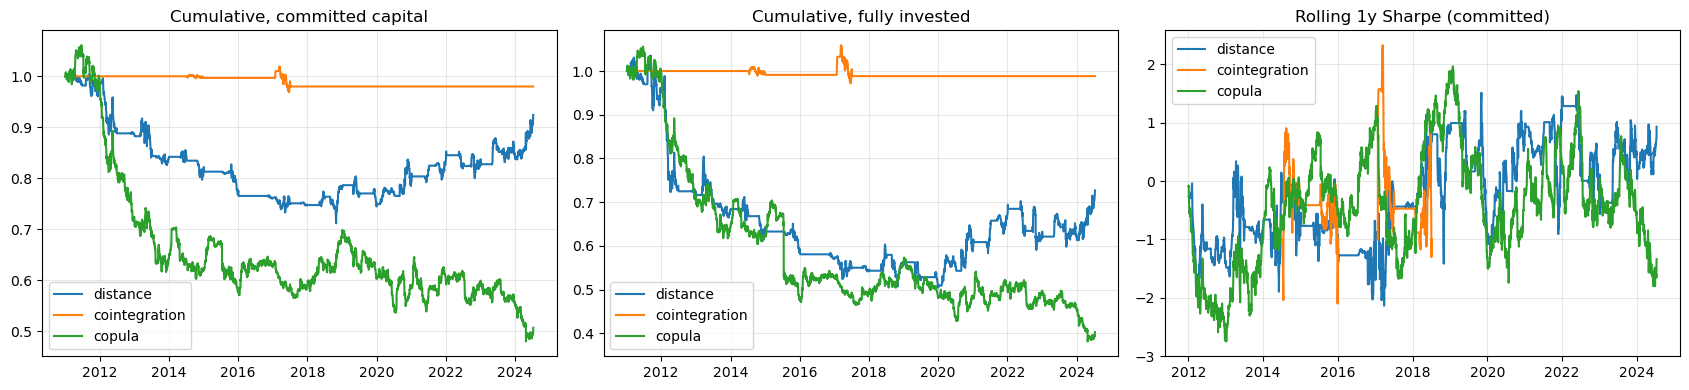

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for m, r in results.items():
    ax[0].plot((1+r["committed"]).cumprod(), label=m)
    ax[1].plot((1+r["invested"]).cumprod(), label=m)
    rr = r["committed"]; ax[2].plot(rr.rolling(252).mean()/rr.rolling(252).std()*np.sqrt(252), label=m)
for a_, t in zip(ax, ["Cumulative, committed capital", "Cumulative, fully invested", "Rolling 1y Sharpe (committed)"]):
    a_.set_title(t); a_.legend(); a_.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 5.3 Which copula fits best?
Analogue of Paper 1 Figure 1 / Table 4. Selection by raw log-likelihood (Paper 1) versus BIC (penalises the extra parameters of the mixtures). If the mixtures win under log-likelihood but not under BIC, the 'superiority of mixtures' is partly a parameter-count effect.

Pairs-windows fitted: 81


,log-likelihood,BIC
Mixture CtG,79.0,7.4
Mixture CFG,19.8,0.0
Student-t,1.2,51.9
Clayton,0.0,14.8
Gaussian,0.0,14.8
Frank,0.0,9.9
Gumbel,0.0,1.2


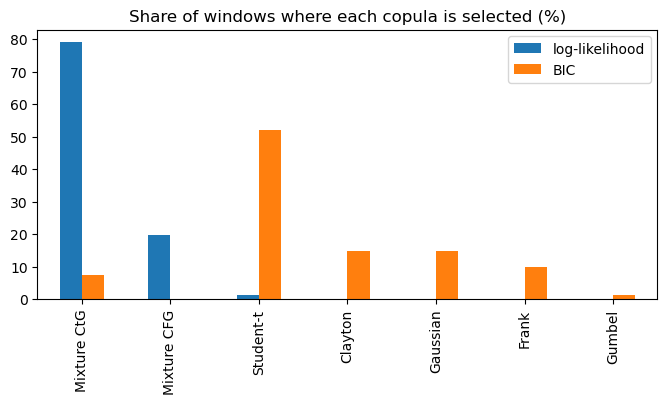

best_ll,Mixture CFG,Mixture CtG,Student-t
pair,,,
AAPL/GOOG,7,20,0
DIA/SPY,0,27,0
IBM/SPY,9,17,1


In [16]:
lg = results["copula"]["log"]
print("Pairs-windows fitted:", len(lg))
cmp = pd.concat({"log-likelihood": lg["best_ll"].value_counts(normalize=True)*100,
                 "BIC": lg["best_bic"].value_counts(normalize=True)*100}, axis=1).fillna(0).round(1)
display(cmp)
cmp.plot.bar(figsize=(8, 3.5), title="Share of windows where each copula is selected (%)"); plt.show()
display(lg.groupby("pair")["best_ll"].value_counts().unstack(fill_value=0))

### 5.4 Per-pair results
With so few pairs, the portfolio can hide large differences. This reruns each pair on its own (committed capital, one pair).

In [17]:
rows = []
for pr in PAIRS:
    for m in ["distance", "cointegration", "copula"]:
        c, e, _ = run_strategy(prices, [pr], m, form=FORM, trade=TRADE, delta=DELTA,
                               cost_rt=COST_BPS/1e4, lag=LAG, verbose=False)
        s = perf(c, m); s["pair"] = f"{pr[0]}/{pr[1]}"; s["method"] = m; rows.append(s)
per_pair = pd.DataFrame(rows).set_index(["pair", "method"])
per_pair[["ann_ret_pct", "ann_vol_pct", "sharpe", "sortino", "max_dd_pct", "nw_tstat"]].round(2)

ann_ret_pct  ann_vol_pct  sharpe  sortino  max_dd_pct  nw_tstat
pair      method                                                                        
AAPL/GOOG distance             -0.88        14.09   -0.06    -0.09       57.83     -0.22
          cointegration         0.71         2.45    0.29     0.48        9.87      0.81
          copula              -10.94        25.84   -0.42    -0.58       91.92     -1.52
IBM/SPY   distance              1.14         8.11    0.14     0.21       24.41      0.52
          cointegration        -1.08         1.96   -0.55    -0.60       15.61     -1.70
          copula               -0.66        16.04   -0.04    -0.06       46.12     -0.15
DIA/SPY   distance             -1.53         2.72   -0.56    -0.78       20.52     -2.13
          cointegration        -0.07         0.63   -0.11    -0.16        1.96     -0.43
          copula               -1.98         4.51   -0.44    -0.61       26.72     -1.64

### 5.5 Trade statistics
The papers stress that results are only comparable when the number of trades is comparable (Paper 1 Table 2). This measures days in market and number of position changes for each method, using the same signals as above.

In [18]:
def trade_stats(method):
    out = []
    rets = prices.pct_change().dropna(); px = prices.loc[rets.index]
    start = FORM
    n_open, n_days, hold = 0, 0, []
    while start + TRADE <= len(px):
        pf, pt = px.iloc[start-FORM:start], px.iloc[start:start+TRADE]
        rf, rt = rets.iloc[start-FORM:start], rets.iloc[start:start+TRADE]
        for a, b in PAIRS:
            try:
                if method == "distance": pos = distance_signals(pf[[a, b]], pt[[a, b]])[0]
                elif method == "cointegration":
                    o = coint_signals(pf[[a, b]], pt[[a, b]]); pos = o[0] if o else np.zeros(len(pt))
                else: pos = copula_signals(rf[[a, b]], rt[[a, b]], delta=DELTA)[0]
            except Exception: pos = np.zeros(len(pt))
            ch = np.flatnonzero(np.diff(np.r_[0, pos]) != 0)
            n_open += int(np.sum((np.diff(np.r_[0, pos]) != 0) & (pos != 0))); n_days += int((pos != 0).sum())
        start += TRADE
    return dict(trades_opened=n_open, avg_days_open=n_days/max(n_open, 1), pct_time_in_market=100*n_days/(len(px)-FORM)/len(PAIRS))
display(pd.DataFrame({m: trade_stats(m) for m in ["distance", "cointegration", "copula"]}).T.round(2))

,trades_opened,avg_days_open,pct_time_in_market
distance,51.0,56.51,27.29
cointegration,5.0,59.00,2.79
copula,231.0,40.19,87.91


### 5.6 Robustness: execution lag and copula threshold
- **Execution lag:** the papers trade at the same close the signal is computed on, which is optimistic. `LAG=1` enters/exits one day later.
- **Threshold:** Paper 1 uses 0.2, Paper 2 uses 0.5, and Paper 2 reports (Table 7) that results are fairly insensitive. Do not choose the threshold that looks best on the full sample and then call it out-of-sample.

In [19]:
if RUN_ROBUSTNESS:
    rows = []
    for lag in [0, 1]:
        for m in ["distance", "cointegration"]:
            c, _, _ = run_strategy(prices, PAIRS, m, form=FORM, trade=TRADE, cost_rt=COST_BPS/1e4, lag=lag, verbose=False)
            s = perf(c, m); s["lag"] = lag; s["setting"] = m; rows.append(s)
        c, _, _ = run_strategy(prices, PAIRS, "copula", form=FORM, trade=TRADE, delta=DELTA, cost_rt=COST_BPS/1e4, lag=lag, verbose=False)
        s = perf(c, "copula"); s["lag"] = lag; s["setting"] = f"copula d={DELTA}"; rows.append(s)
    for d in [0.1, 0.3, 0.5]:
        c, _, _ = run_strategy(prices, PAIRS, "copula", form=FORM, trade=TRADE, delta=d, cost_rt=COST_BPS/1e4, lag=LAG, verbose=False)
        s = perf(c, "copula"); s["lag"] = LAG; s["setting"] = f"copula d={d}"; rows.append(s)
    rob = pd.DataFrame(rows).set_index(["setting", "lag"])
    display(rob[["ann_ret_pct", "ann_vol_pct", "sharpe", "sortino", "max_dd_pct", "nw_tstat"]].round(2))

,,ann_ret_pct,ann_vol_pct,sharpe,sortino,max_dd_pct,nw_tstat
setting,lag,,,,,,
distance,0.0,-0.42,5.66,-0.07,-0.11,29.55,-0.27
cointegration,0.0,-0.15,0.97,-0.15,-0.21,4.94,-0.54
copula d=0.2,0.0,-4.53,10.12,-0.45,-0.62,54.81,-1.61
distance,1.0,-0.45,5.56,-0.08,-0.12,28.53,-0.30
cointegration,1.0,-0.04,1.13,-0.04,-0.06,5.29,-0.12
copula d=0.2,1.0,-5.36,10.11,-0.53,-0.73,59.61,-1.94
copula d=0.1,0.0,-4.72,10.22,-0.46,-0.64,55.90,-1.67
copula d=0.3,0.0,-4.17,10.01,-0.42,-0.58,52.80,-1.51
copula d=0.5,0.0,-3.17,9.44,-0.34,-0.47,44.48,-1.22


### 5.7 Factor regression (Fama-French 5 + momentum)
Regresses daily committed-capital excess returns on Ken French's daily factors (Mkt-RF, SMB, HML, RMW, CMA, Mom), with Newey-West (6 lags) errors, as in Paper 1 Table 3 / Paper 2 Table 6. The **intercept** is the alpha not explained by the factors (shown in % per day; x252 for a rough annual figure). The cell downloads the factor files from Ken French's data library; if your network blocks this, download the two CSV zips manually and point `read_ff` at them. The papers also add long-term reversal (Paper 1) or Pastor-Stambaugh liquidity (Paper 2); these are omitted here because they are separate downloads / WRDS data.

In [20]:
import io, zipfile, urllib.request, statsmodels.api as sm
BASE = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"
def read_ff(name):
    raw = urllib.request.urlopen(BASE + name, timeout=30).read()
    txt = zipfile.ZipFile(io.BytesIO(raw)).read(zipfile.ZipFile(io.BytesIO(raw)).namelist()[0]).decode("latin1")
    lines = [l for l in txt.splitlines() if l[:8].strip().isdigit() and len(l.split(",")[0].strip()) == 8]
    df = pd.read_csv(io.StringIO("\n".join(lines)), header=None, index_col=0)
    df.index = pd.to_datetime(df.index.astype(str), format="%Y%m%d"); return df/100
try:
    ff5 = read_ff("F-F_Research_Data_5_Factors_2x3_daily_CSV.zip"); ff5.columns = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "RF"]
    mom = read_ff("F-F_Momentum_Factor_daily_CSV.zip"); mom.columns = ["Mom"]
    ff = ff5.join(mom, how="inner")
    out = []
    for m, r in results.items():
        d = pd.concat([r["committed"].rename("y"), ff], axis=1, join="inner").dropna()
        fit = sm.OLS(d["y"] - d["RF"], sm.add_constant(d.drop(columns=["y", "RF"]))).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
        out.append(pd.Series({"alpha_%/day": 100*fit.params["const"], "alpha_t": fit.tvalues["const"],
                              "beta_mkt": fit.params["Mkt-RF"], "t_mkt": fit.tvalues["Mkt-RF"],
                              "beta_mom": fit.params["Mom"], "t_mom": fit.tvalues["Mom"], "adj_R2": fit.rsquared_adj}, name=m))
    display(pd.DataFrame(out).round(4))
except Exception as e:
    print("Factor download failed (", repr(e)[:80], "). Download from Ken French's library manually.")

,alpha_%/day,alpha_t,beta_mkt,t_mkt,beta_mom,t_mom,adj_R2
distance,-0.0049,-0.7977,-0.0043,-0.6447,-0.0526,-6.5889,0.0339
cointegration,-0.0048,-4.3179,-0.0004,-0.7157,-0.0018,-1.5895,-0.0002
copula,-0.0213,-1.9282,-0.0026,-0.1713,-0.0026,-0.1660,0.0054


### 5.8 Is the copula-minus-distance difference significant?
Stationary bootstrap (Politis-Romano) of the difference in annualised mean return and Sharpe ratio between copula and distance (committed capital), 2,000 resamples, block length 10 days. This is a simplified version of the Ledoit-Wolf procedure the paper uses (the paper also averages optimal block lengths). With three pairs and a short sample, expect wide intervals.

In [23]:
from arch.bootstrap import StationaryBootstrap
d = pd.concat([results["copula"]["committed"], results["distance"]["committed"]], axis=1, join="inner").dropna().values
def stat(a, b):
    ma, mb, sa, sb = a.mean()*252, b.mean()*252, a.std()*np.sqrt(252), b.std()*np.sqrt(252)
    return np.array([ma-mb, ma/sa - mb/sb])
bs = StationaryBootstrap(10, d[:, 0], d[:, 1], seed=1)
draws = np.array([stat(*x[0]) - stat(d[:, 0], d[:, 1]) for x in bs.bootstrap(2000)])
obs = stat(d[:, 0], d[:, 1])
# centred bootstrap two-sided p-values
pv = [(np.abs(draws[:, i]) >= abs(obs[i])).mean() for i in range(2)]
pd.DataFrame({"observed": obs, "p_value": pv}, index=["mean return diff (ann.)", "Sharpe diff"]).round(4)

,observed,p_value
mean return diff (ann.),-0.0405,0.1560
Sharpe diff,-0.3673,0.2685
